# L16 — Segmentation and Vision Transformers — Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L16-Segmentation/L16_Segmentation_Transformers.ipynb)

This notebook accompanies **Lecture 16**. L15's detectors drew a **box** around each object. Today we go one step
further and label **pixels**.

1. **Semantic segmentation**: give every pixel a class (road / not road). An FCN and a small U-Net, trained here
   on a 1968 air photo, with labels made from a modern road map.
2. **Instance segmentation**: one mask per object (cabin 1, cabin 2, …). Mask R-CNN's idea, a trained YOLO-seg,
   and SAM turning L15's 26 cabin boxes into 26 cabin masks.
3. **Vision Transformers (ViT)**: cut the photo into patches, treat them like words, and let every patch *attend*
   to every other patch. Attention by hand, then a pretrained ViT on the cabin court.

Everything runs on a CPU in about 6–8 minutes; most of that is §4 (training two small networks, about 5 minutes).
On Colab, switch to a GPU (Runtime → Change runtime type) and §4 takes well under a minute.

| Section | Topic |
|---------|-------|
| 0 | Setup and data |
| 1 | A mask is an image of labels; pixel accuracy vs IoU |
| 2 | Upsampling by hand: nearest and transposed convolution |
| 3 | Two small networks: an FCN and a U-Net |
| 4 | Training both on the 1968 roads |
| 5 | Testing on the east strip: sharp vs blurry, and roads the map forgot |
| 6 | Semantic vs instance; a trained YOLO-seg on the cabin court |
| 7 | SAM: from L15's boxes to masks |
| 8 | ViT step 1: a photo as 196 patches |
| 9 | ViT step 2: attention by hand |
| 10 | A pretrained ViT: where does a cabin patch look? |
| 11 | Try at home |

In [2]:
import json, os, time
os.environ["YOLO_VERBOSE"] = "False"          # keep the ultralytics package quiet (set before importing it)
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY, BLUE = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                                    "#1A3A5C", "#7B4EA0", "#7A8FA6", "#4A7BD0")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("OpenCV", cv2.__version__, "| PyTorch", torch.__version__, "| device:", DEVICE)

OpenCV 5.0.0 | PyTorch 2.15.0+cu132 | device: cpu


## 0 · Setup and data

`L16.zip` (5.2 MB) holds

* `roads_1968.jpg`: a 4 × 4 km piece of the **1968** Queens County air-photo mosaic (north of North Wiltshire),
  4096 × 4096 pixels at 1 m per pixel;
* `roads_label.png`: the matching label image, 0 = not road, 1 = road, 255 = ignore (see §1);
* `court.png` and `cabins_gt.json`: L15's 1950 cabin court and its 26 hand-drawn boxes.

The pretrained weights (YOLO-seg 6 MB, SAM 2.1 tiny 78 MB, ViT-B/16 346 MB) download from GitHub the first
time they are used. Safe to re-run.

In [3]:
import io, urllib.request, zipfile

BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch_zip(name, needed):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=120) as r:
        blob = r.read()
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        z.extractall(".")
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded and extracted")

fetch_zip("L16.zip", ["L16/roads_1968.jpg", "L16/roads_label.png", "L16/court.png", "L16/cabins_gt.json"])
photo = cv2.imread("L16/roads_1968.jpg", cv2.IMREAD_GRAYSCALE)       # 4096 x 4096, 1 m / pixel
label = cv2.imread("L16/roads_label.png", cv2.IMREAD_GRAYSCALE)      # 0 / 1 / 255
court = cv2.imread("L16/court.png", cv2.IMREAD_GRAYSCALE)            # 1950 cabin court, 1400 x 422
GT = np.array(json.load(open("L16/cabins_gt.json"))["boxes"])       # 26 cabins, (x1, y1, x2, y2)
print("photo", photo.shape, "| label values", np.unique(label), "| court", court.shape, "| cabins", len(GT))

L16.zip: already present
photo (4096, 4096) | label values [  0   1 255] | court (422, 1400) | cabins 26


In [4]:
import subprocess, sys
for pkg in ["ultralytics", "timm"]:
    try:
        __import__(pkg)
    except ImportError:                   # Colab has timm; ultralytics installs in about 30 s
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)
import ultralytics, timm
print("ultralytics", ultralytics.__version__, "| timm", timm.__version__)

ultralytics 8.4.216 | timm 1.0.31


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · A mask is an image of labels

**Classification** gives one label per photo, **detection** (L15) one box per object, and **semantic
segmentation** one label **per pixel**. The answer is itself an image, the same size as the photo, holding a
class number in every pixel. That image is called a **mask**.

Where did our road mask come from? Nobody painted 4096 × 4096 pixels by hand. We took the **2024 National Road
Network** (the road centre-lines of PEI), drew each road 7 pixels (≈ 7 m) wide, and shifted the lines a few metres
to sit on the 1968 roads. Around one junction the roads were **rebuilt after 1968**, so the 2024 map is simply wrong
there; those pixels are marked 255 = *ignore* and play no part in training or scoring.

road pixels:       108,792  (0.65% of the photo)
ignore pixels:     597,600


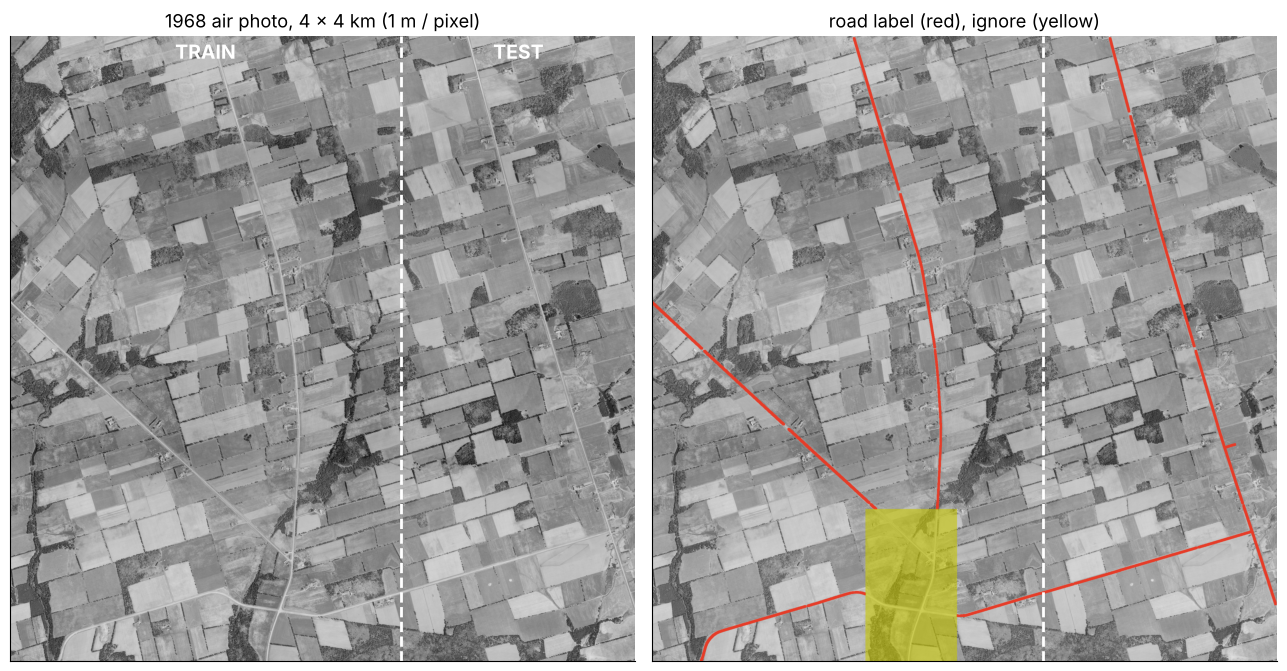

In [5]:
road = label == 1
print(f"road pixels:    {road.sum():>10,}  ({100*road.mean():.2f}% of the photo)")
print(f"ignore pixels:  {(label == 255).sum():>10,}")

fig, ax = plt.subplots(1, 2, figsize=(13, 6.6))
ax[0].imshow(photo, cmap="gray"); ax[0].set_title("1968 air photo, 4 × 4 km (1 m / pixel)")
over = np.dstack([photo] * 3).copy()
k = cv2.dilate(road.astype(np.uint8), np.ones((9, 9))) > 0          # fatten the lines so they show at this size
over[k] = (230, 60, 40); over[label == 255] = (over[label == 255] * 0.4 + np.array([200, 200, 0]) * 0.6).astype(np.uint8)
ax[1].imshow(over); ax[1].set_title("road label (red), ignore (yellow)")
for a in ax:
    a.axvline(2560, color="white", lw=2, ls="--"); a.set_xticks([]); a.set_yticks([])
ax[0].text(1280, 150, "TRAIN", color="white", fontsize=14, ha="center", weight="bold")
ax[0].text(3330, 150, "TEST", color="white", fontsize=14, ha="center", weight="bold")
plt.tight_layout(); plt.show()

**Scoring a mask.** Count pixels into four kinds, just like L15's precision and recall:
TP (road, called road), FP (not road, called road), FN (road, missed), TN (not road, called not road).

* **Pixel accuracy** = (TP + TN) / all pixels.
* **IoU** for the road class = TP / (TP + FP + FN): the overlap of predicted road and true road, divided by their
  union. Same idea as box IoU in L15, but counting pixels.

The by-hand example from the slides: a 6 × 6 image whose true road is one column of 6 pixels.

In [6]:
def scores(pred, truth, ignore=None):
    keep = np.ones_like(truth, bool) if ignore is None else ~ignore
    p, t = pred[keep].astype(bool), truth[keep].astype(bool)
    tp, fp, fn, tn = (p & t).sum(), (p & ~t).sum(), (~p & t).sum(), (~p & ~t).sum()
    return dict(TP=int(tp), FP=int(fp), FN=int(fn), acc=(tp + tn) / p.size, IoU=tp / max(tp + fp + fn, 1))

truth = np.zeros((6, 6), int); truth[:, 2] = 1
A = np.zeros((6, 6), int)                                   # says "no road" everywhere
B = np.zeros((6, 6), int); B[0:5, 2] = 1; B[0:3, 3] = 1     # 8 pixels called road, 5 of them right
C = np.zeros((6, 6), int); C[1:5, 2] = 1                    # your turn
for name, P in [("A", A), ("B", B), ("C", C)]:
    s = scores(P, truth)
    print(f"{name}: TP {s['TP']}  FP {s['FP']}  FN {s['FN']}   accuracy {s['acc']:.2f}   road IoU {s['IoU']:.2f}")

A: TP 0  FP 0  FN 6   accuracy 0.83   road IoU 0.00
B: TP 5  FP 3  FN 1   accuracy 0.89   road IoU 0.56
C: TP 4  FP 0  FN 2   accuracy 0.94   road IoU 0.67


A's accuracy (0.83) looks fine, yet it found **no road at all**. On the real photo the problem is far worse,
because roads are well under 1% of the pixels:

In [7]:
ign = label == 255
s = scores(np.zeros_like(label), road, ign)
print(f"'no road anywhere' on the whole photo: accuracy {s['acc']:.4f}, road IoU {s['IoU']:.2f}")

'no road anywhere' on the whole photo: accuracy 0.9933, road IoU 0.00


So for thin or rare classes (roads, buildings, shoreline) report **IoU**, never plain pixel accuracy.

## 2 · Upsampling by hand

A classification CNN **shrinks** the image (L13: every 2 × 2 pooling halves the width and height). To label every
pixel we must **grow** the small map back to full size. Two ways:

* **nearest**: copy each value into a 2 × 2 block (no learning);
* **transposed convolution** (`nn.ConvTranspose2d`): stamp a **learned** 2 × 2 kernel, scaled by each input value.

The slide's example: input [[1, 2], [0, 3]] and kernel K = [[1, 0], [1, 1]].

In [8]:
x = torch.tensor([[1., 2.], [0., 3.]])[None, None]              # shape (batch, channels, H, W) = (1, 1, 2, 2)
near = F.interpolate(x, scale_factor=2, mode="nearest")
tconv = nn.ConvTranspose2d(1, 1, kernel_size=2, stride=2, bias=False)
with torch.no_grad():
    tconv.weight[:] = torch.tensor([[1., 0.], [1., 1.]])        # in a real network this kernel is learned
print("nearest:\n", near[0, 0].int().numpy())
print("transposed conv:\n", tconv(x)[0, 0].int().detach().numpy())

nearest:
 [[1 1 2 2]
 [1 1 2 2]
 [0 0 3 3]
 [0 0 3 3]]
transposed conv:
 [[1 0 2 0]
 [1 1 2 2]
 [0 0 3 0]
 [0 0 3 3]]


## 3 · Two small networks: an FCN and a U-Net

Both start with the **same encoder**: four rounds of (two 3 × 3 convolutions, then 2 × 2 max-pooling), so a
256 × 256 tile becomes a 16 × 16 grid with 128 channels. Then:

* **FCN** (fully convolutional network, 2015): a 1 × 1 convolution turns each of the 16 × 16 cells into two
  scores (not road, road), and the scores are stretched back to 256 × 256 (bilinear). One cell covers 16 × 16
  pixels, so the edges come out blurry.
* **U-Net** (2015, first for microscope images): grows back one step at a time (transposed convolutions), and at
  each size it **concatenates** the encoder's map of the same size (the *skip connections*, like ResNet's in L13).
  The decoder gets the fine detail back from the encoder.

In [9]:
def block(cin, cout):                 # two 3x3 conv layers, each with batch norm and ReLU (L13)
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(),
                         nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU())

class Encoder(nn.Module):
    def __init__(self, c=8):
        super().__init__()
        self.d1, self.d2, self.d3, self.d4 = block(1, c), block(c, 2*c), block(2*c, 4*c), block(4*c, 8*c)
        self.bottom = block(8*c, 16*c)
    def forward(self, x):
        x1 = self.d1(x)                          # 256 x 256 x 8
        x2 = self.d2(F.max_pool2d(x1, 2))        # 128 x 128 x 16
        x3 = self.d3(F.max_pool2d(x2, 2))        #  64 x  64 x 32
        x4 = self.d4(F.max_pool2d(x3, 2))        #  32 x  32 x 64
        b = self.bottom(F.max_pool2d(x4, 2))     #  16 x  16 x 128
        return x1, x2, x3, x4, b

class FCN(nn.Module):
    def __init__(self, c=8):
        super().__init__()
        self.enc = Encoder(c); self.score = nn.Conv2d(16*c, 2, 1)
    def forward(self, x):
        b = self.enc(x)[-1]
        return F.interpolate(self.score(b), size=x.shape[-2:], mode="bilinear", align_corners=False)

class UNet(nn.Module):
    def __init__(self, c=8):
        super().__init__()
        self.enc = Encoder(c)
        self.up4, self.c4 = nn.ConvTranspose2d(16*c, 8*c, 2, 2), block(16*c, 8*c)
        self.up3, self.c3 = nn.ConvTranspose2d(8*c, 4*c, 2, 2), block(8*c, 4*c)
        self.up2, self.c2 = nn.ConvTranspose2d(4*c, 2*c, 2, 2), block(4*c, 2*c)
        self.up1, self.c1 = nn.ConvTranspose2d(2*c, c, 2, 2), block(2*c, c)
        self.score = nn.Conv2d(c, 2, 1)
    def forward(self, x):
        x1, x2, x3, x4, b = self.enc(x)
        y = self.c4(torch.cat([self.up4(b), x4], 1))     # grow to 32 x 32, glue on the encoder's 32 x 32 map
        y = self.c3(torch.cat([self.up3(y), x3], 1))     # 64 x 64
        y = self.c2(torch.cat([self.up2(y), x2], 1))     # 128 x 128
        y = self.c1(torch.cat([self.up1(y), x1], 1))     # 256 x 256
        return self.score(y)

for Net in (FCN, UNet):
    n = Net(); out = n(torch.zeros(1, 1, 256, 256))
    print(f"{Net.__name__:5s}: {sum(p.numel() for p in n.parameters()):,} parameters, "
          f"input (1, 1, 256, 256) -> output {tuple(out.shape)}")
print("encoder shapes:", [tuple(t.shape[1:]) for t in Encoder()(torch.zeros(1, 1, 256, 256))])

FCN  : 296,154 parameters, input (1, 1, 256, 256) -> output (1, 2, 256, 256)
UNet : 487,154 parameters, input (1, 1, 256, 256) -> output (1, 2, 256, 256)
encoder shapes: [(8, 256, 256), (16, 128, 128), (32, 64, 64), (64, 32, 32), (128, 16, 16)]


## 4 · Training both on the 1968 roads

Training is ordinary classification (L12), done at **every pixel**: the loss is the cross-entropy averaged over all
pixels of a batch of random 256 × 256 tiles from the **west** part of the photo (x < 2560). Two details:

* Roads are rare, so road pixels get **5 ×** the weight in the loss; otherwise "never say road" is nearly optimal.
* Pixels labelled 255 are skipped (`ignore_index=255`).
* Each tile is randomly flipped and rotated by 90° steps (L14's augmentation): roads run in every direction.

`ITERS = 400` takes about 3.5 min (U-Net) + 1.5 min (FCN) on a CPU, under a minute in total on a Colab GPU.

In [10]:
X = photo.astype(np.float32) / 255.0
SPLIT, TILE, ITERS, BATCH = 2560, 256, 400, 8

def random_batch(rng, n=BATCH):
    xs, ys = [], []
    for _ in range(n):
        y0, x0 = rng.integers(0, 4096 - TILE), rng.integers(0, SPLIT - TILE)
        xi, yi = X[y0:y0+TILE, x0:x0+TILE], label[y0:y0+TILE, x0:x0+TILE]
        if rng.random() < 0.5: xi, yi = xi[:, ::-1], yi[:, ::-1]
        k = rng.integers(4); xi, yi = np.rot90(xi, k), np.rot90(yi, k)
        xs.append(xi.copy()); ys.append(yi.copy())
    return torch.tensor(np.array(xs))[:, None].to(DEVICE), torch.tensor(np.array(ys)).long().to(DEVICE)

def train(Net, seed=0):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    net = Net().to(DEVICE); opt = torch.optim.Adam(net.parameters(), 2e-3)
    w = torch.tensor([1.0, 5.0], device=DEVICE)              # road pixels count 5x
    t, losses = time.time(), []
    for it in range(ITERS):
        net.train(); xb, yb = random_batch(rng)
        loss = F.cross_entropy(net(xb), yb, weight=w, ignore_index=255)
        opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
        if it % 100 == 0 or it == ITERS - 1:
            print(f"  {Net.__name__} iter {it:3d}  loss {loss.item():.3f}  ({time.time()-t:.0f} s)")
    return net, losses

nets, curves = {}, {}
for Net in (FCN, UNet):
    nets[Net.__name__], curves[Net.__name__] = train(Net)

  FCN iter   0  loss 0.510  (0 s)


  FCN iter 100  loss 0.067  (19 s)


  FCN iter 200  loss 0.030  (38 s)


  FCN iter 300  loss 0.077  (57 s)


  FCN iter 399  loss 0.016  (76 s)


  UNet iter   0  loss 0.628  (1 s)


  UNet iter 100  loss 0.138  (48 s)


  UNet iter 200  loss 0.059  (98 s)


  UNet iter 300  loss 0.068  (153 s)


  UNet iter 399  loss 0.027  (206 s)


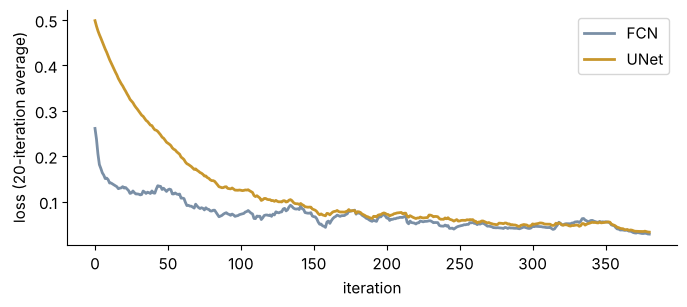

In [11]:
plt.figure(figsize=(7, 3.2))
for name, col in (("FCN", GREY), ("UNet", GOLD)):
    l = np.convolve(curves[name], np.ones(20) / 20, mode="valid")
    plt.plot(l, color=col, lw=2, label=name)
plt.xlabel("iteration"); plt.ylabel("loss (20-iteration average)"); plt.legend(); plt.tight_layout(); plt.show()

## 5 · Testing on the east strip

The test strip (x ≥ 2560, 1536 × 4096 pixels) was never seen in training. A fully convolutional network does not
care about the input size, so we can run it on the whole strip in one go.

In [12]:
def predict(net, img):
    net.eval()
    with torch.no_grad():
        x = torch.tensor(img)[None, None].to(DEVICE)
        return torch.softmax(net(x), 1)[0, 1].cpu().numpy()        # probability of "road" at every pixel

test_img, test_lab = X[:, SPLIT:], label[:, SPLIT:]
prob = {name: predict(net, test_img) for name, net in nets.items()}
for name in ("FCN", "UNet"):
    s = scores(prob[name] > 0.5, test_lab == 1, test_lab == 255)
    print(f"{name:5s}: accuracy {s['acc']:.4f}   road IoU {s['IoU']:.2f}   (TP {s['TP']:,}  FP {s['FP']:,}  FN {s['FN']:,})")
s = scores(np.zeros_like(test_lab), test_lab == 1, test_lab == 255)
print(f"no road: accuracy {s['acc']:.4f}   road IoU {s['IoU']:.2f}")

FCN  : accuracy 0.9938   road IoU 0.34   (TP 20,450  FP 12,090  FN 27,195)
UNet : accuracy 0.9921   road IoU 0.45   (TP 40,196  FP 42,165  FN 7,449)
no road: accuracy 0.9924   road IoU 0.00


All three round to the same accuracy, 0.99; the U-Net's is even a little **lower** than "no road anywhere".
IoU separates them. Look at **where** the differences are:
the probability maps (bright = road) and the errors (green = right road, red = called road but not in the map,
blue = missed).

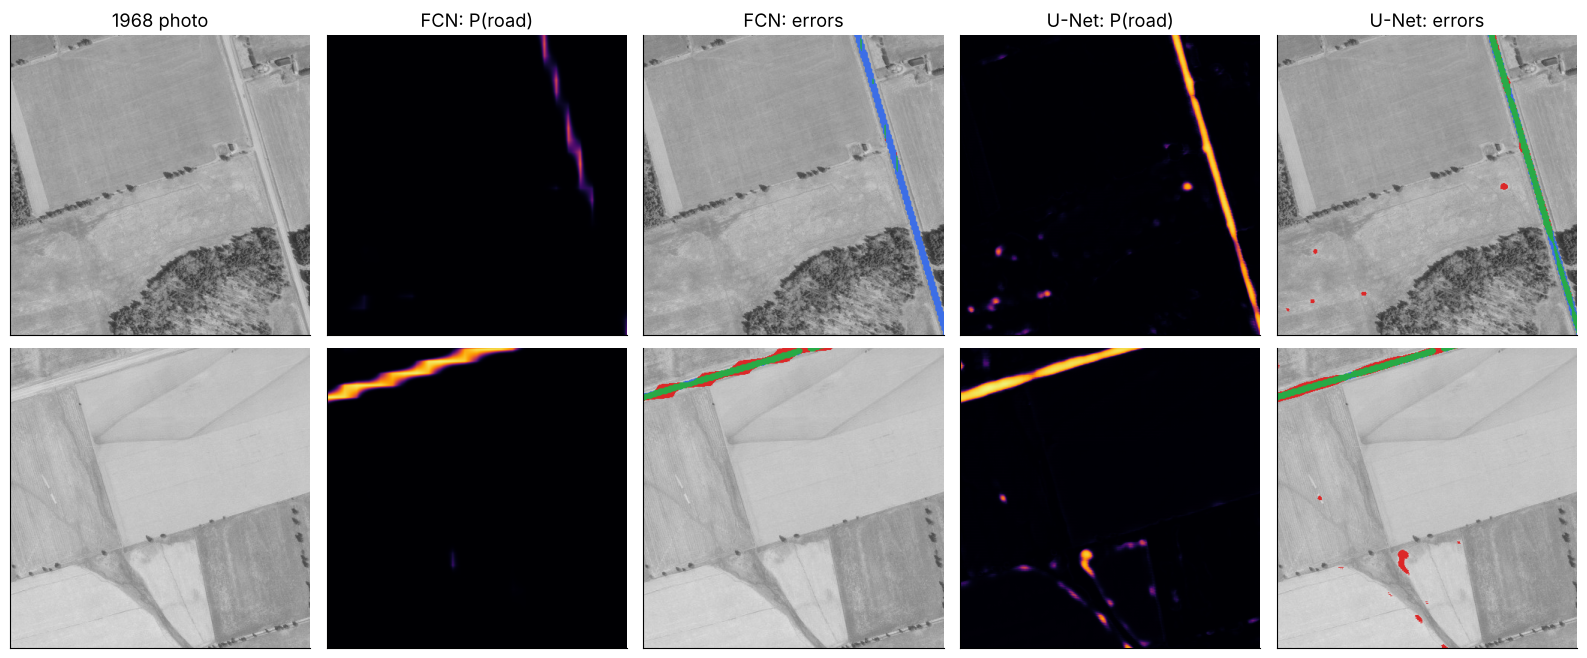

In [13]:
def err_rgb(img, p, lab):
    o = np.dstack([(img * 255).astype(np.uint8)] * 3).copy(); pr, g = p > 0.5, lab == 1
    o[pr & g] = (40, 170, 70); o[pr & (lab == 0)] = (220, 40, 40); o[~pr & g] = (60, 110, 230)
    return o

zooms = [(1500, 550), (3350, 800)]                 # (row, column) in the test strip
fig, ax = plt.subplots(2, 5, figsize=(16, 6.8))
for r, (y, x) in enumerate(zooms):
    sl = np.s_[y:y+400, x:x+400]
    ax[r, 0].imshow(test_img[sl], cmap="gray", vmin=0, vmax=1)
    for c, name in enumerate(("FCN", "UNet")):
        ax[r, 1 + 2*c].imshow(prob[name][sl], cmap="inferno", vmin=0, vmax=1)
        ax[r, 2 + 2*c].imshow(err_rgb(test_img[sl], prob[name][sl], test_lab[sl]))
for c, t in enumerate(["1968 photo", "FCN: P(road)", "FCN: errors", "U-Net: P(road)", "U-Net: errors"]):
    ax[0, c].set_title(t)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

* The **FCN**'s road is a wobbly band with steps every 16 pixels: it only ever decided at 16 × 16 resolution.
  It also misses most of the vertical road in the top row.
* The **U-Net**'s road is a thin, crisp line that follows the real road edge: the skip connections gave the
  decoder the full-resolution detail.
* Some U-Net "false roads" (red) are **real** farm lanes and driveways that the 2024 road map never had, and some
  are places nobody could label for sure (close-ups below). The labels are not perfect, so the score is not either.
  This matters for your projects: if your labels come from a modern map, a "mistake" on a 1935 photo may be the
  map's mistake.

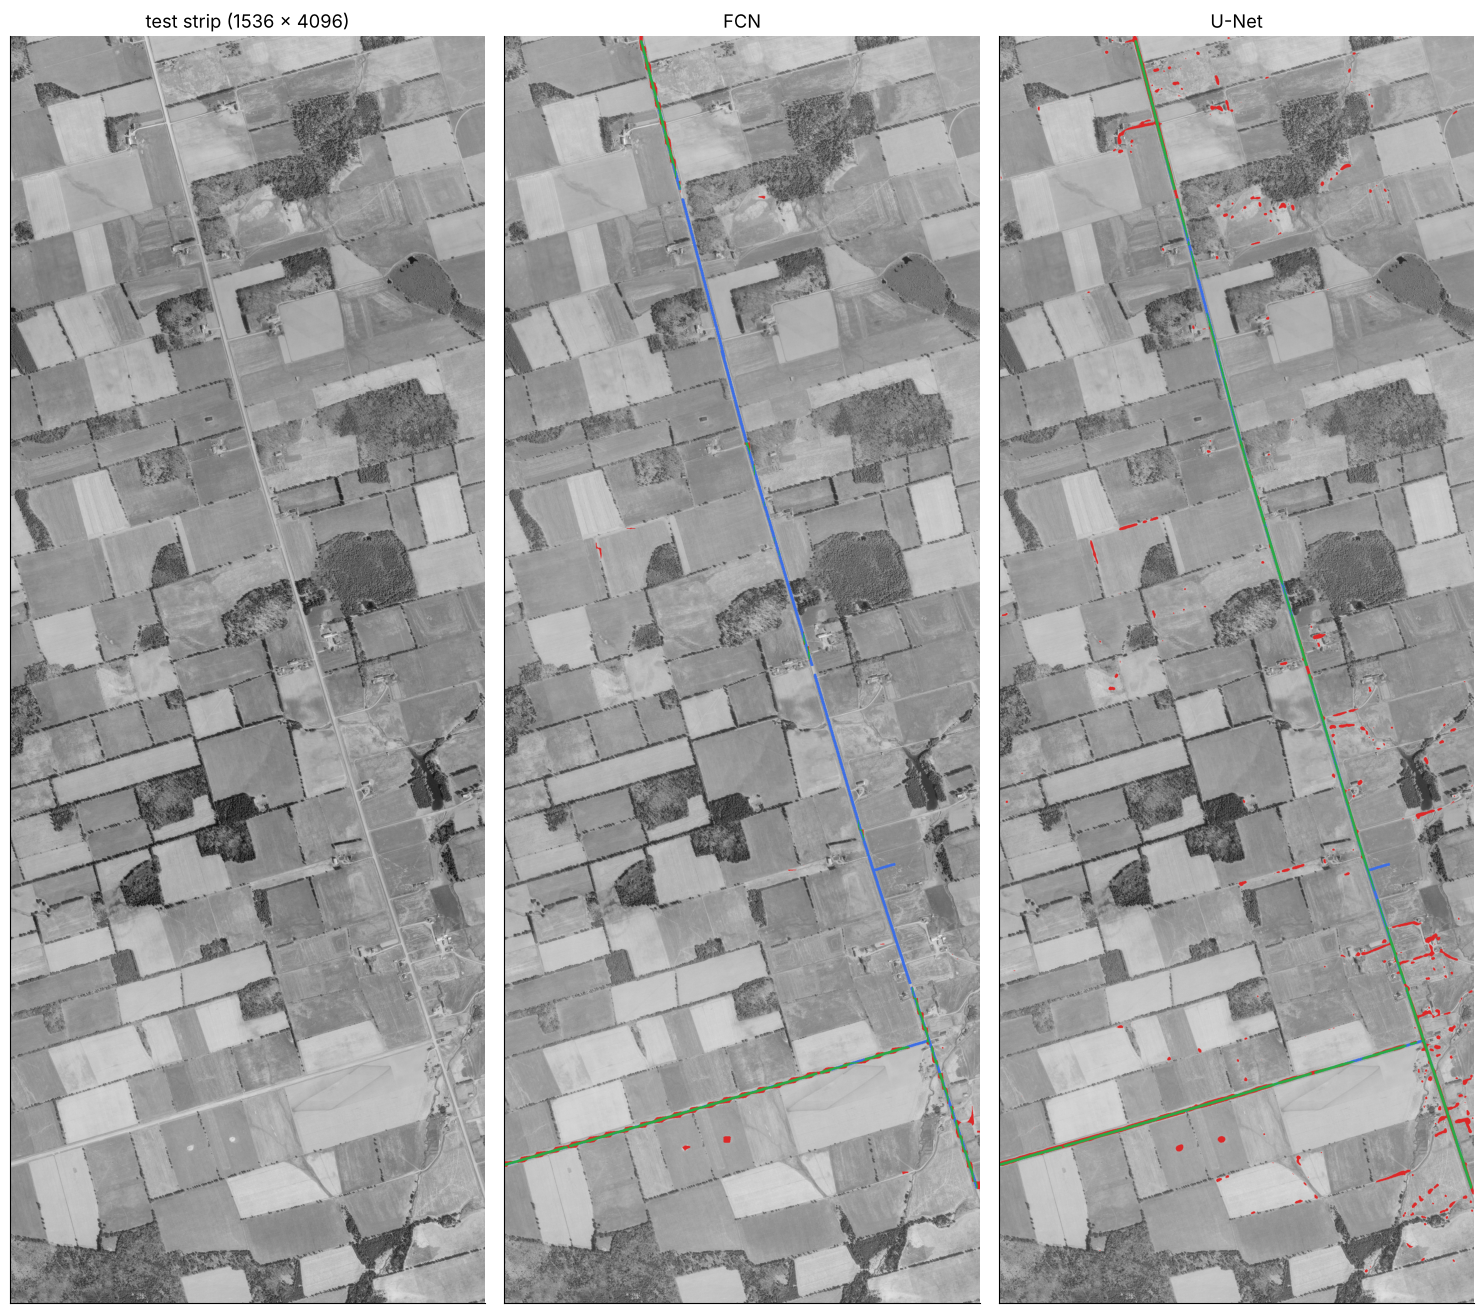

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 13))
ax[0].imshow(test_img, cmap="gray"); ax[0].set_title("test strip (1536 × 4096)")
ax[1].imshow(err_rgb(test_img, prob["FCN"], test_lab)); ax[1].set_title("FCN")
ax[2].imshow(err_rgb(test_img, prob["UNet"], test_lab)); ax[2].set_title("U-Net")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

**Two close-ups of the U-Net's red** (both in the test strip):

* **Left: red, but right.** A curved farm lane runs from the road to a farmstead. It is plainly there in 1968, and
  the U-Net traces all of it, but the 2024 road map never had it, so every pixel counts as a "false road".
* **Right: red, but who knows?** Pale strips along the edges of fields. A farm track, or just the edge of a ploughed
  field? Even by eye it is hard to say. Old photos are full of places like this, where a careful person could label
  either way.

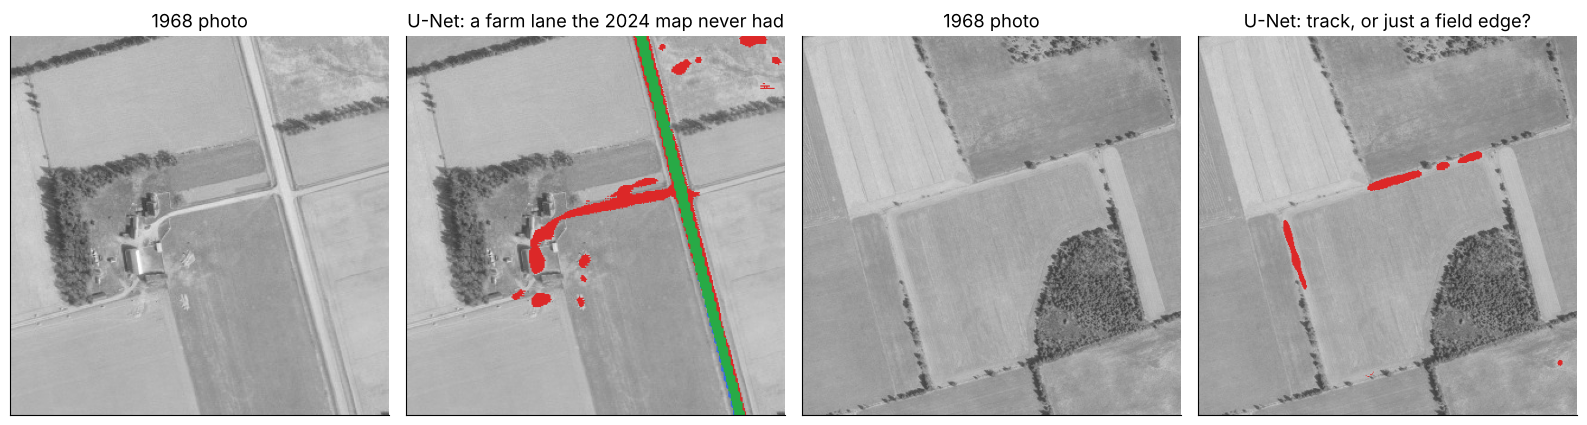

In [15]:
spots = [("a farm lane the 2024 map never had", 150, 279, 320),      # (title, row, column, size) in the test strip
         ("track, or just a field edge?", 1426, 200, 420)]
fig, ax = plt.subplots(1, 4, figsize=(16, 4.4))
for k, (title, y, x, S) in enumerate(spots):
    sl = np.s_[y:y+S, x:x+S]
    ax[2*k].imshow(test_img[sl], cmap="gray", vmin=0, vmax=1); ax[2*k].set_title("1968 photo")
    ax[2*k + 1].imshow(err_rgb(test_img[sl], prob["UNet"][sl], test_lab[sl])); ax[2*k + 1].set_title("U-Net: " + title)
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 6 · Semantic vs instance segmentation

A semantic mask says *which pixels are cabin*. When two cabins touch, their pixels merge into one blob, and
counting the blobs (connected components, L5) gives the wrong answer. **Instance segmentation** gives each object
its own mask: cabin 1, cabin 2, …

The slide's toy example: two touching 4 × 4 cabins.

In [16]:
toy = np.zeros((7, 10), np.uint8); toy[1:5, 1:5] = 1; toy[2:6, 5:9] = 1      # semantic mask: 1 = cabin
n, _ = cv2.connectedComponents(toy)
print("cabin pixels:", toy.sum(), "| connected blobs:", n - 1, "(the truth is 2 cabins)")

cabin pixels: 32 | connected blobs: 1 (the truth is 2 cabins)


**Mask R-CNN** (2017) is L15's Faster R-CNN plus one small extra branch: for **each box**, a tiny FCN predicts a
28 × 28 mask, which is then stretched to the size of the box. Detection first, then a mask inside each box.

Today's trained instance segmenter is **YOLO11n-seg**, the same idea in the YOLO family (one line, like L15's
YOLO). It was trained on COCO's 80 classes, which include *car*, *boat* and *train* but no *cabin*.

0.80 s | 10 objects: [('boat', 0.6), ('boat', 0.53), ('boat', 0.51), ('boat', 0.5), ('boat', 0.39), ('boat', 0.38), ('boat', 0.35), ('boat', 0.31), ('boat', 0.27), ('boat', 0.26)]


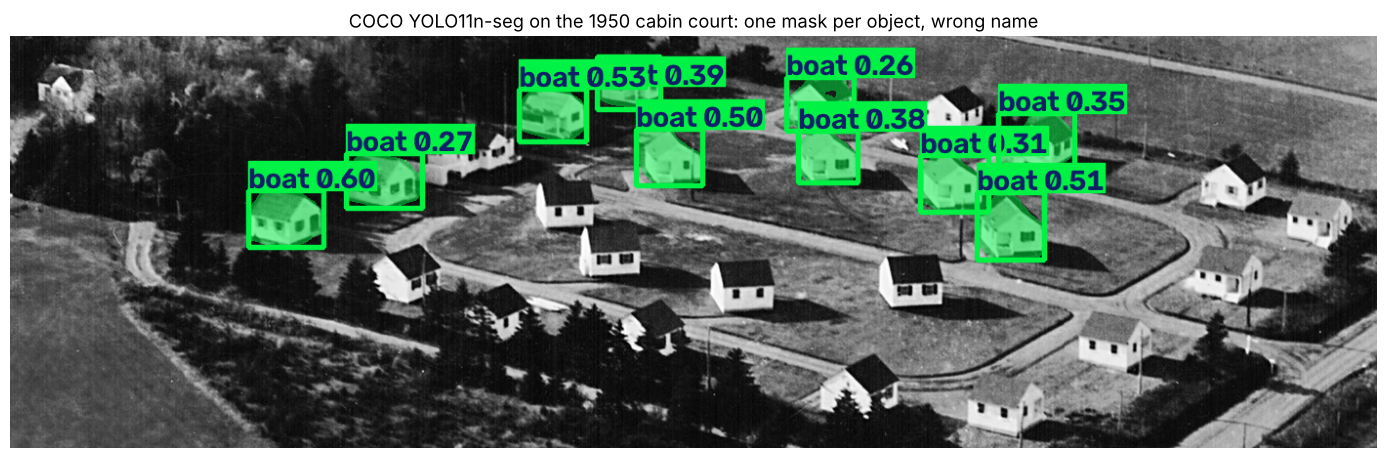

In [17]:
from ultralytics import YOLO
seg = YOLO("yolo11n-seg.pt")                           # 6 MB, downloaded on first use
t = time.time()
res = seg.predict(cv2.cvtColor(court, cv2.COLOR_GRAY2BGR), imgsz=640, conf=0.25, verbose=False, retina_masks=True)[0]
print(f"{time.time()-t:.2f} s | {len(res.boxes)} objects:",
      [(res.names[int(c)], round(float(s), 2)) for c, s in zip(res.boxes.cls, res.boxes.conf)])
plt.figure(figsize=(14, 4.6)); plt.imshow(res.plot()[:, :, ::-1]); plt.axis("off")
plt.title("COCO YOLO11n-seg on the 1950 cabin court: one mask per object, wrong name"); plt.tight_layout(); plt.show()

Same lesson as L15 ("train"): **where** the objects are transfers, **what** they are does not. Every mask sits on
a cabin, but the network calls them *boats*. Fine-tuning (L14, AL9) on a few labelled cabins would fix the name.

## 7 · SAM: from L15's boxes to masks

**SAM** (Segment Anything, Meta 2023; SAM 2 in 2024) is a *promptable* segmenter: you give it a click or a box,
and it returns the mask of the thing there. It has no class names at all. Give it L15's 26 cabin boxes as prompts
and we get 26 cabin masks, without any training. (The SAM helper notebook and AL10 use it on your project tiles.)

26 masks in 7.9 s
mask area / box area: median 0.79, range 0.63 - 0.94
pixels claimed by two masks: 0


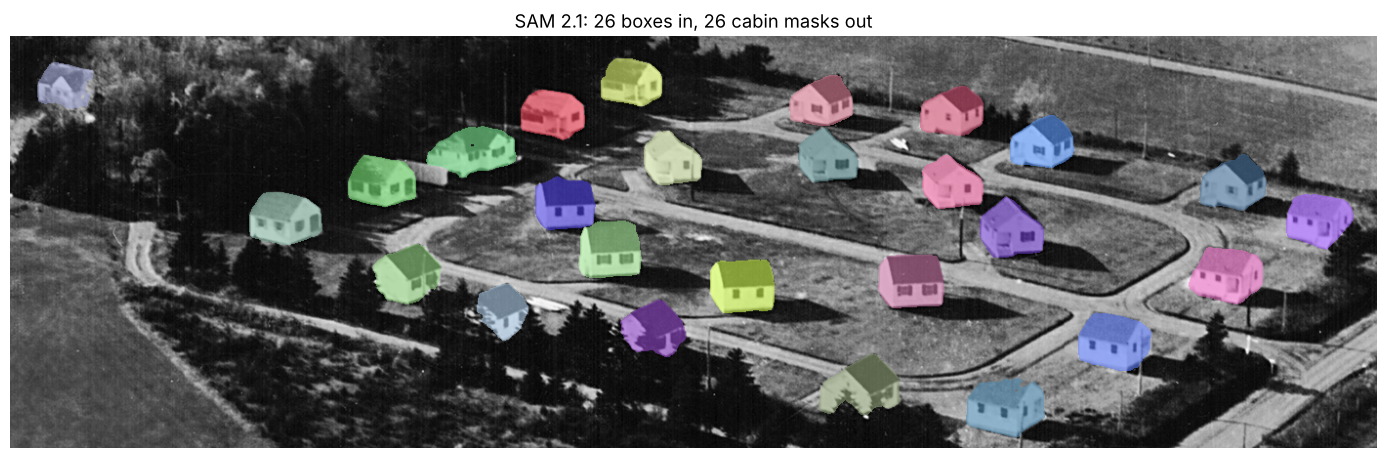

In [18]:
from ultralytics import SAM
sam = SAM("sam2.1_t.pt")                               # SAM 2.1 tiny, 78 MB, downloaded on first use
t = time.time()
r = sam(cv2.cvtColor(court, cv2.COLOR_GRAY2BGR), bboxes=GT.tolist(), verbose=False)[0]
M = r.masks.data.cpu().numpy().astype(bool)           # 26 masks, each 422 x 1400
print(f"{len(M)} masks in {time.time()-t:.1f} s")

box_area = (GT[:, 2] - GT[:, 0]) * (GT[:, 3] - GT[:, 1])
fill = M.sum((1, 2)) / box_area
print(f"mask area / box area: median {np.median(fill):.2f}, range {fill.min():.2f} - {fill.max():.2f}")
print("pixels claimed by two masks:", int((M.sum(0) > 1).sum()))

over = np.dstack([court] * 3).astype(np.float32); rng = np.random.default_rng(1)
for m in M:
    over[m] = 0.4 * over[m] + 0.6 * rng.integers(60, 255, 3)
plt.figure(figsize=(14, 4.6)); plt.imshow(over.astype(np.uint8)); plt.axis("off")
plt.title("SAM 2.1: 26 boxes in, 26 cabin masks out"); plt.tight_layout(); plt.show()

A box over-counts: a cabin fills only about three quarters of its box (the rest is grass and shadow). If you want
**areas** (roof area, field area, water area), you want masks, not boxes.

## 8 · ViT step 1: a photo as 196 patches

A **transformer** (2017) reads a sentence as a list of word *tokens*. The **Vision Transformer** (ViT, 2020) reads
a photo the same way: cut it into 16 × 16 patches and treat each patch as one word.

By hand: a 224 × 224 colour photo → (224 / 16)² = 14 × 14 = **196 patches**, each 16 × 16 × 3 = **768 numbers**.
ViT adds one extra token, **[CLS]**, whose final value is used for the class: 197 tokens in all.

We use a square piece of the cabin court (x 700 to 1122) shrunk to 224 × 224.

crop (224, 224, 3) -> patches (196, 768)


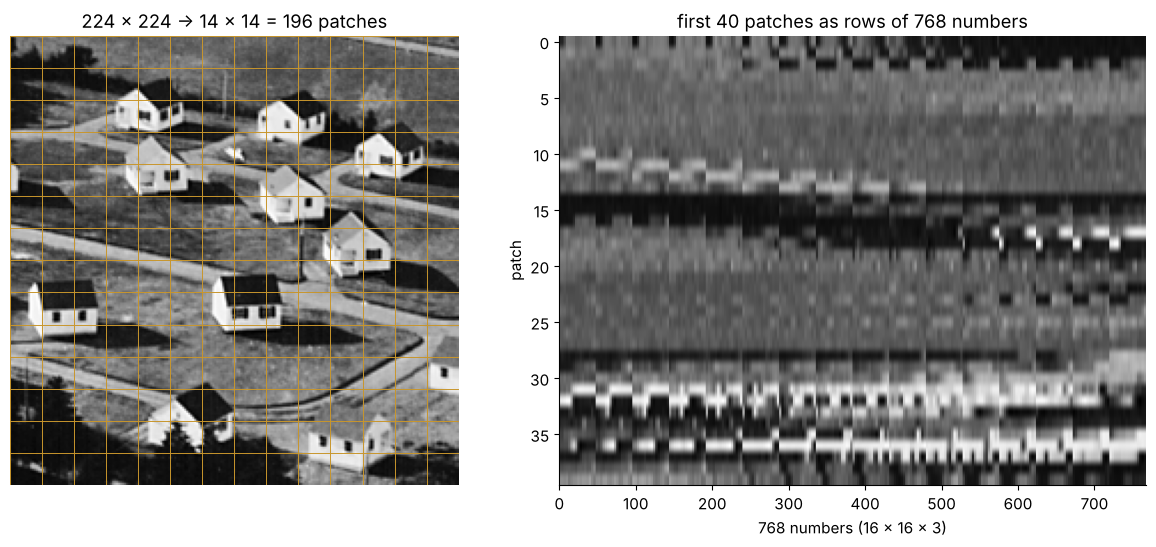

In [19]:
from PIL import Image
X0 = 700
crop = np.array(Image.fromarray(court[:, X0:X0+422]).convert("RGB").resize((224, 224), Image.BICUBIC))
P = 16
patches = crop.reshape(14, P, 14, P, 3).transpose(0, 2, 1, 3, 4).reshape(196, P*P*3)   # 196 rows of 768 numbers
print("crop", crop.shape, "-> patches", patches.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax[0].imshow(crop)
for k in range(15):
    ax[0].axhline(k*P - 0.5, color=GOLD, lw=0.7); ax[0].axvline(k*P - 0.5, color=GOLD, lw=0.7)
ax[0].set_title("224 × 224 → 14 × 14 = 196 patches"); ax[0].axis("off")
ax[1].imshow(patches[:40], aspect="auto", cmap="gray"); ax[1].set_title("first 40 patches as rows of 768 numbers")
ax[1].set_xlabel("768 numbers (16 × 16 × 3)"); ax[1].set_ylabel("patch")
plt.tight_layout(); plt.show()

Each 768-number row then goes through one learned linear layer (a matrix multiply) to become the patch's token,
and a learned **position** vector is added so the model knows where the patch came from (the order of words
matters in a sentence; so does the position of a patch).

## 9 · ViT step 2: attention by hand

In a CNN, a 3 × 3 filter only looks at its **neighbours**. In **attention**, every token looks at **every** token,
and decides how much to borrow from each:

1. **score** = how similar am I to token j? (a dot product, q · k);
2. **weights** = softmax of the scores (positive, summing to 1);
3. **output** = weighted average of the tokens' values.

The slide's example: three tokens, *cabin A*, *grass*, *cabin B*. Cabin A asks "who looks like me?"

In [20]:
def softmax(s):
    e = np.exp(s - np.max(s)); return e / e.sum()

q = np.array([1.0, 0.0])                               # cabin A's question ("query")
K = np.array([[2.0, 0.0],                              # keys: cabin A
              [0.0, 1.0],                              #       grass
              [2.0, 1.0]])                             #       cabin B
V = np.array([[1.0, 0.0],                              # values: (cabin-ness, grass-ness)
              [0.0, 1.0],
              [1.0, 0.0]])
score = K @ q
w = softmax(score)
fmt = lambda v: "(" + ", ".join(f"{t:.2f}" for t in v) + ")"
print("scores  ", fmt(score))
print("weights ", fmt(w), " sum", f"{w.sum():.2f}")
print("output  ", fmt(w @ V), "  <- mostly 'cabin'")
print("\nyour turn, scores (1, 0, 0): weights", fmt(softmax(np.array([1.0, 0.0, 0.0]))))

scores   (2.00, 0.00, 2.00)
weights  (0.47, 0.06, 0.47)  sum 1.00
output   (0.94, 0.06)   <- mostly 'cabin'

your turn, scores (1, 0, 0): weights (0.58, 0.21, 0.21)


In a real ViT the queries, keys and values are 64-number vectors made from each token by learned matrices, the
scores are divided by √64 = 8, and there are 12 such *heads* side by side in each of 12 layers. The idea is the
three lines above.

**Cost.** 196 patches means 196² = 38,416 scores per head per layer (a few more with [CLS]): fine. A 1024 × 1024 image with 16-pixel
patches has 4,096 tokens and 16.8 million scores per head per layer, one reason SAM takes seconds per image.

In [21]:
for side in (224, 384, 1024):
    n = (side // 16) ** 2
    print(f"{side} x {side}: {n:5,} patches -> {n*n:12,} attention scores per head per layer")

224 x 224:   196 patches ->       38,416 attention scores per head per layer
384 x 384:   576 patches ->      331,776 attention scores per head per layer
1024 x 1024: 4,096 patches ->   16,777,216 attention scores per head per layer


## 10 · A pretrained ViT: where does a cabin patch look?

ViT-B/16 (86 M parameters) pretrained on ImageNet-21k (14 million photos) and fine-tuned on ImageNet's 1,000
classes. ViTs need a lot of data to train from scratch, so in practice you **always** start from pretrained weights
(L14). The weights (346 MB) come from the `timm` project's GitHub releases.

In [22]:
vit = timm.create_model("vit_base_patch16_224", pretrained=False)
url = ("https://github.com/rwightman/pytorch-image-models/releases/download/"
       "v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth")
vit.load_state_dict(torch.hub.load_state_dict_from_url(url, map_location="cpu")); vit.eval()
print(f"ViT-B/16: {sum(p.numel() for p in vit.parameters())/1e6:.1f} M parameters, "
      f"{len(vit.blocks)} layers, {vit.blocks[0].attn.num_heads} heads")

# record every layer's attention weights while the model runs (a forward hook)
ATT = []
def keep_attention(module, inputs, output):
    x = inputs[0]; B, N, C = x.shape; H = module.num_heads
    qkv = module.qkv(x).reshape(B, N, 3, H, C // H).permute(2, 0, 3, 1, 4)
    ATT.append(((qkv[0] * module.scale) @ qkv[1].transpose(-2, -1)).softmax(-1)[0].detach())
for blk in vit.blocks:
    blk.attn.register_forward_hook(keep_attention)

x = (torch.tensor(crop / 255.0, dtype=torch.float32).permute(2, 0, 1)[None] - 0.5) / 0.5   # this model's normalisation
ATT.clear()
with torch.no_grad():
    p = vit(x).softmax(-1)[0]
from timm.data import ImageNetInfo
info = ImageNetInfo()
top = p.topk(3)
print("top 3:", [(info.index_to_description(int(i)).split(",")[0], round(float(v), 2)) for v, i in zip(top.values, top.indices)])

ViT-B/16: 86.6 M parameters, 12 layers, 12 heads


top 3: [('beacon', 0.46), ('picket fence', 0.1), ('barn', 0.09)]


ImageNet has no *cabin court* class, so the label is a near miss again (L15's "train", §6's "boat").
The interesting part is inside. Pick the patch on the front of the cabin in the middle (row 8, column 7: the red
square in §8's grid on the slides) and look at its attention weights to the other 195 patches in layers 1–4.

cabin patches: 40 of 196 = 20% of the photo; query patch on a cabin: True
layer 1: share of its attention on (other) cabin patches = 26%
layer 2: share of its attention on (other) cabin patches = 48%
layer 3: share of its attention on (other) cabin patches = 47%
layer 4: share of its attention on (other) cabin patches = 45%


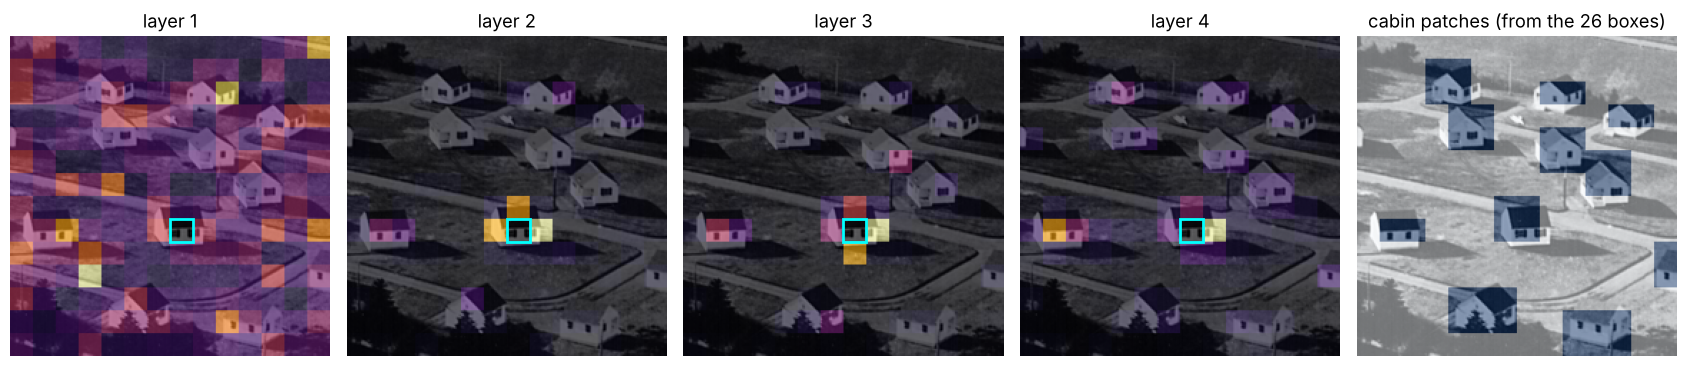

In [23]:
cab = np.zeros((14, 14), bool)                         # which patches have their centre inside a cabin box?
sc = 224 / 422
for x1, y1, x2, y2 in GT:
    for r in range(14):
        for c in range(14):
            cx, cy = c*16 + 8, r*16 + 8
            if (x1 - X0)*sc <= cx <= (x2 - X0)*sc and y1*sc <= cy <= y2*sc:
                cab[r, c] = True
qr, qc = 8, 7
q_idx = 1 + qr*14 + qc                                 # +1 because token 0 is [CLS]
print(f"cabin patches: {cab.sum()} of 196 = {cab.mean():.0%} of the photo; query patch on a cabin: {cab[qr, qc]}")

fig, ax = plt.subplots(1, 5, figsize=(17, 3.9))
for i, L in enumerate([0, 1, 2, 3]):
    a = ATT[L].mean(0)[q_idx, 1:].reshape(14, 14).numpy()     # average the 12 heads; drop [CLS]
    a[qr, qc] = 0; a = a / a.sum()                            # leave out the patch itself
    print(f"layer {L+1}: share of its attention on (other) cabin patches = {a[cab].sum():.0%}")
    heat = cv2.resize(a / a.max(), (224, 224), interpolation=cv2.INTER_NEAREST)
    ax[i].imshow(crop); ax[i].imshow(heat, cmap="inferno", alpha=0.6)
    ax[i].add_patch(plt.Rectangle((qc*16 - 0.5, qr*16 - 0.5), 16, 16, fill=False, ec="cyan", lw=2))
    ax[i].set_title(f"layer {L+1}"); ax[i].axis("off")
ax[4].imshow(crop); ax[4].imshow(np.kron(cab, np.ones((16, 16))), cmap="Blues", alpha=0.45)
ax[4].set_title("cabin patches (from the 26 boxes)"); ax[4].axis("off")
plt.tight_layout(); plt.show()

Cabin patches are about a fifth of the photo, but in layers 2–4 the cabin patch puts close to half of its attention
on **other cabins**, including ones 150 pixels away. A CNN's 3 × 3 filters would need many layers before one cabin
could "see" another that far away. That reach, and the fact that it runs on any list of tokens (words, patches,
clicks), is why transformers are now inside many vision models, including SAM's image encoder.

## 11 · Try at home

1. **Thresholds.** In §5, score the U-Net at thresholds 0.3 and 0.7 instead of 0.5. Which way does IoU move,
   and why (think FP vs FN)?
2. **No weighting.** Train the U-Net with `w = [1, 1]`. What happens to the road IoU? To the accuracy?
3. **Ask SAM with clicks.** Replace the boxes in §7 by one click per cabin at the box centre
   (`sam(img, points=[[cx, cy]], labels=[1])`). How many masks are still good?
4. **Another query.** In §10, pick a grass patch (e.g. row 12, column 3). Where does it look?
5. **Projects.** Which kind of segmentation does your project need: semantic (water, fields, forest, roads) or
   instance (buildings, individual fields)? Where would your labels come from?